170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 24s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 73ms/step - accuracy: 0.4074 - loss: 1.6106 - val_accuracy: 0.5358 - val_loss: 1.3085
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 71ms/step - accuracy: 0.5525 - loss: 1.2530 - val_accuracy: 0.5992 - val_loss: 1.1540
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 73ms/step - accuracy: 0.6120 - loss: 1.0992 - val_accuracy: 0.6328 - val_loss: 1.0449
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 71ms/step - accuracy: 0.6472 - loss: 1.0000 - val_accuracy: 0.6410 - val_loss: 1.0181
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 71ms/step - accuracy: 0.6785 - loss: 0.9171 - val_accuracy: 0.6702 - val_loss: 0.9621
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6701 - loss: 0.9664
Test Accuracy: 0.6700999736785889


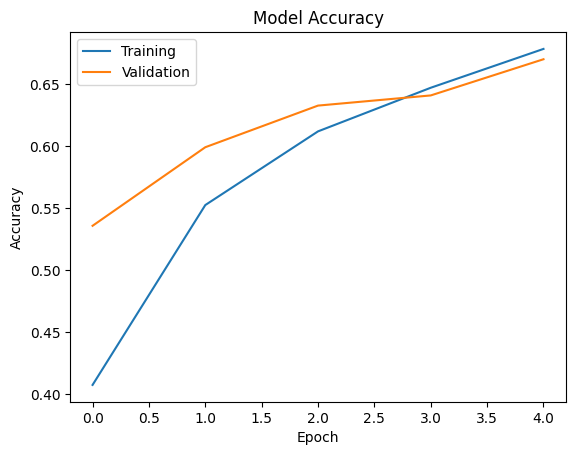

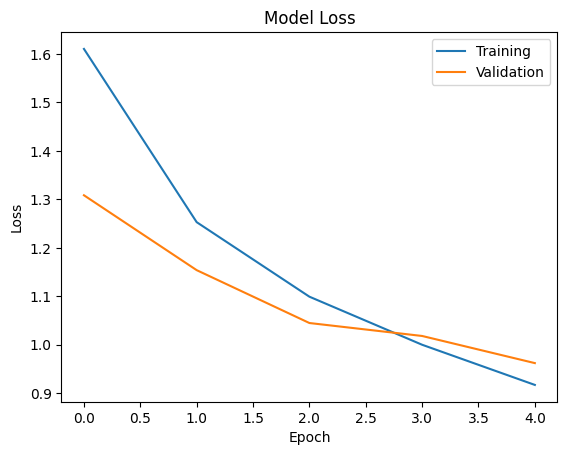

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

(X_train, y_train), (X_test, y_test) = cifar10.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

model = Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])
plt.title("Model Accuracy")
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])
plt.title("Model Loss")
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.2746 - val_loss: 0.1884
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1705 - val_loss: 0.1532
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1443 - val_loss: 0.1339
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1290 - val_loss: 0.1215
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.1185 - val_loss: 0.1131
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


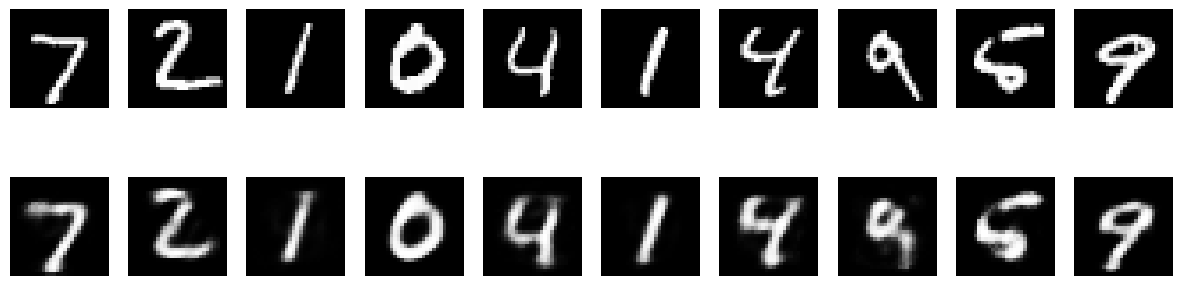

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

(X_train, _), (X_test, _) = mnist.load_data()
X_train = X_train.reshape(-1, 784).astype("float32") / 255.0
X_test = X_test.reshape(-1, 784).astype("float32") / 255.0

input_img = tf.keras.Input(shape=(784,))
encoded = layers.Dense(32, activation="relu")(input_img)
decoded = layers.Dense(784, activation="sigmoid")(encoded)

autoencoder = Model(input_img, decoded)

autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

autoencoder.fit(X_train, X_train, epochs=5, batch_size=256, validation_data=(X_test, X_test))

decoded_imgs = autoencoder.predict(X_test)

plt.figure(figsize=(15, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.show()

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


704/704 ━━━━━━━━━━━━━━━━━━━━ 115s 159ms/step - accuracy: 0.7972 - loss: 0.4323 - val_accuracy: 0.8280 - val_loss: 0.4571
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 110s 156ms/step - accuracy: 0.8884 - loss: 0.2774 - val_accuracy: 0.8460 - val_loss: 0.3739
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 109s 155ms/step - accuracy: 0.9245 - loss: 0.1976 - val_accuracy: 0.8276 - val_loss: 0.4000
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 109s 155ms/step - accuracy: 0.9475 - loss: 0.1414 - val_accuracy: 0.8396 - val_loss: 0.4725
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 142s 155ms/step - accuracy: 0.9668 - loss: 0.0937 - val_accuracy: 0.8148 - val_loss: 0.5209
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 48ms/step - accuracy: 0.8142 - loss: 0.5444
Test Accuracy: 0.8141599893569946


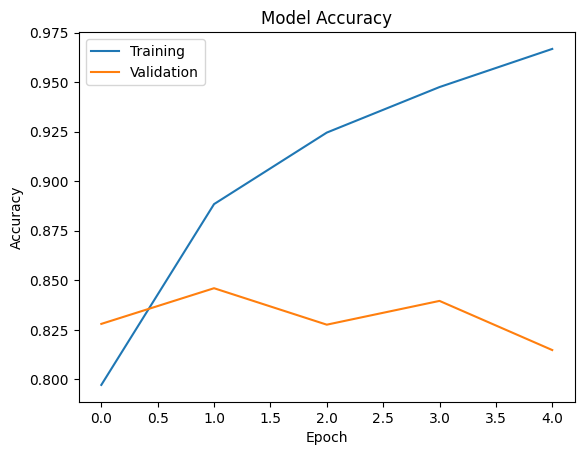

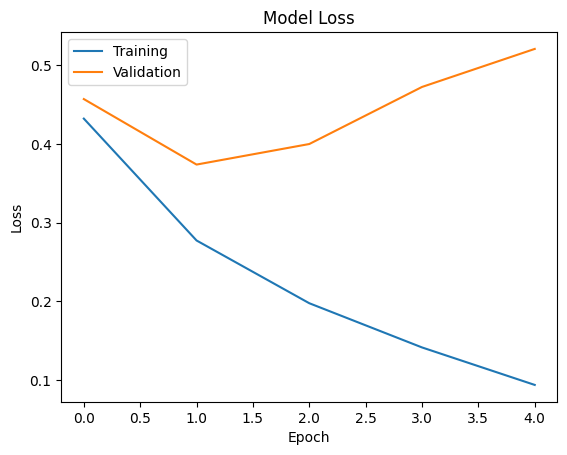

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
import matplotlib.pyplot as plt

max_features = 10000
maxlen = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=max_features)

X_train = sequence.pad_sequences(X_train, maxlen=maxlen)
X_test = sequence.pad_sequences(X_test, maxlen=maxlen)

model = models.Sequential([
    layers.Embedding(max_features, 128, input_length=maxlen),
    layers.LSTM(128),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])
plt.title("Model Accuracy")
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])
plt.title("Model Loss")
plt.show()